In [ ]:
from matplotlib import pyplot as plt
import pandas as pd
import time
import datetime
import numpy as np

sleeps = pd.read_csv("sleeps108.csv")
dailies = pd.read_csv("dailies108.csv")

sleeps['summaryId'] = sleeps['summaryId'].astype(str).str[:8]
dailies['summaryId'] = dailies['summaryId'].astype(str).str[:8]
sleeps = sleeps[sleeps['deepSleepDurationInSeconds'] != 0]
sleeps = sleeps[sleeps['remSleepInSeconds'] != 0]
dailies = dailies[dailies['activeKilocalories'] != 0]
dailies = dailies[dailies['activeTimeInSeconds'] != 0]

new_sleeps = sleeps[['id','summaryId', 'date', 'startTimeInSeconds', 'startTimeOffsetInSeconds', 'durationInSeconds',
                     'deepSleepDurationInSeconds', 'lightSleepDurationInSeconds', 'remSleepInSeconds']]
new_dailies = dailies[['id','summaryId', 'date','averageStressLevel', 'activeKilocalories', 'activeTimeInSeconds']]

sleeps_dailies = pd.merge(new_sleeps, new_dailies, on = ["id","summaryId", "date"], how = "inner")

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.min_rows', 15)

In [ ]:
temp = []
for x in range(len(sleeps_dailies)):
  temp.append(int(sleeps_dailies['startTimeInSeconds'][x] + sleeps_dailies['startTimeOffsetInSeconds'][x] + sleeps_dailies['durationInSeconds'][x]))

date = []
time_hms = []
for time_stamp in temp:
  struct_time = time.localtime(time_stamp)
  dateString = time.strftime("%Y-%m-%d", struct_time)
  timeString = time.strftime("%H:%M:%S", struct_time)
  date.append(dateString)
  time_hms.append(timeString)

sleeps_dailies['Date'] = date
sleeps_dailies['time'] = time_hms

In [ ]:
temp = []
for x in range(len(sleeps_dailies)):
  temp.append(int(sleeps_dailies['startTimeInSeconds'][x] + sleeps_dailies['startTimeOffsetInSeconds'][x] + sleeps_dailies['durationInSeconds'][x]))

date = []
time_hms = []
for time_stamp in temp:
  struct_time = time.localtime(time_stamp)
  dateString = time.strftime("%Y-%m-%d", struct_time)
  timeString = time.strftime("%H:%M:%S", struct_time)
  date.append(dateString)
  time_hms.append(timeString)

sleeps_dailies['Date'] = date
sleeps_dailies['time'] = time_hms

percentage_deep = []
percentage_rem = []
sleeps_dailies['totalSleepInHours'] = 0
sleeps_dailies['averageActiveIntensity'] = 0

for index, row in sleeps_dailies.iterrows():
    sleeps_dailies.at[index, 'totalSleepInHours'] = (row['deepSleepDurationInSeconds'] + row['lightSleepDurationInSeconds'] + row['remSleepInSeconds'])/3600

for index, row in sleeps_dailies.iterrows():
    sleeps_dailies.at[index, 'averageActiveIntensity'] = (row['activeKilocalories'] / row['activeTimeInSeconds'])*60

for  x in range(len(sleeps_dailies)):
    total_sleep_time = sleeps_dailies.iloc[x]['deepSleepDurationInSeconds'] + sleeps_dailies.iloc[x]['lightSleepDurationInSeconds']
    + sleeps_dailies.iloc[x]['remSleepInSeconds']

    deep_sleep_time = sleeps_dailies.iloc[x]['deepSleepDurationInSeconds']
    rem_sleep_time = sleeps_dailies.iloc[x]['remSleepInSeconds']

    proportion_deep = round(deep_sleep_time / total_sleep_time, 3)
    proportion_rem = round(rem_sleep_time/ total_sleep_time, 3)
    percentage_deep.append(proportion_deep)
    percentage_rem.append(proportion_rem)

sleeps_dailies['totalSleepInHours'] = sleeps_dailies['totalSleepInHours'].round(3)
sleeps_dailies['averageActiveIntensity'] = sleeps_dailies['averageActiveIntensity'].round(3)
sleeps_dailies['proportion_deep'] = percentage_deep
sleeps_dailies['proportion_rem'] = percentage_rem

In [ ]:
Q1_deep = sleeps_dailies['proportion_deep'].quantile(0.25)
Q3_deep = sleeps_dailies['proportion_deep'].quantile(0.75)

Q1_rem = sleeps_dailies['proportion_rem'].quantile(0.25)
Q3_rem = sleeps_dailies['proportion_rem'].quantile(0.75)

Q1_sleep = sleeps_dailies['totalSleepInHours'].quantile(0.25)
Q3_sleep = sleeps_dailies['totalSleepInHours'].quantile(0.75)

IQR_deep = Q3_deep - Q1_deep
IQR_rem = Q3_rem - Q1_rem
IQR_sleep = Q3_sleep - Q1_sleep

lower_bound_deep = Q1_deep - 1.5 * IQR_deep
upper_bound_deep = Q3_deep + 1.5 * IQR_deep

lower_bound_rem = Q1_rem - 1.5 * IQR_rem
upper_bound_rem = Q3_rem + 1.5 * IQR_rem

lower_bound_sleep = Q1_sleep - 1.5 * IQR_sleep
upper_bound_sleep = Q3_sleep + 1.5 * IQR_sleep

sleeps_dailies = sleeps_dailies[(sleeps_dailies['proportion_deep'] >= lower_bound_deep)&(sleeps_dailies['proportion_deep'] <= upper_bound_deep)]
sleeps_dailies = sleeps_dailies[(sleeps_dailies['proportion_rem'] >= lower_bound_rem)&(sleeps_dailies['proportion_rem'] <= upper_bound_rem)]
sleeps_dailies = sleeps_dailies[(sleeps_dailies['totalSleepInHours'] >= lower_bound_sleep)&(sleeps_dailies['totalSleepInHours'] <= upper_bound_sleep)]

In [ ]:
Q1_stress = sleeps_dailies['averageStressLevel'].quantile(0.25)
Q3_stress = sleeps_dailies['averageStressLevel'].quantile(0.75)

Q1_active = sleeps_dailies['averageActiveIntensity'].quantile(0.25)
Q3_active = sleeps_dailies['averageActiveIntensity'].quantile(0.75)

IQR_stress = Q3_stress - Q1_stress
IQR_active = Q3_active - Q1_active

lower_bound_stress = Q1_stress - 1.5 * IQR_stress
upper_bound_stress = Q3_stress + 1.5 * IQR_stress

lower_bound_active = Q1_active - 1.5 * IQR_active
upper_bound_active = Q3_active + 1.5 * IQR_active

sleeps_dailies = sleeps_dailies[(sleeps_dailies['averageStressLevel'] >= lower_bound_stress)&(sleeps_dailies['averageStressLevel'] <= upper_bound_stress)]
sleeps_dailies = sleeps_dailies[(sleeps_dailies['averageActiveIntensity'] >= lower_bound_active)&(sleeps_dailies['averageActiveIntensity'] <= upper_bound_active)]

In [ ]:
sleeps_dailies_clean = sleeps_dailies[['id','summaryId', 'Date', 'time', 'proportion_deep', 'proportion_rem',
                                       'totalSleepInHours', 'averageStressLevel', 'averageActiveIntensity']]

sleeps_sorted = sleeps_dailies_clean.sort_values(by=['id', 'Date'])
last_entry_per_date = sleeps_sorted.groupby(['id', 'Date']).tail(1)
sleeps_dailies_clean = last_entry_per_date
sleeps_dailies_clean

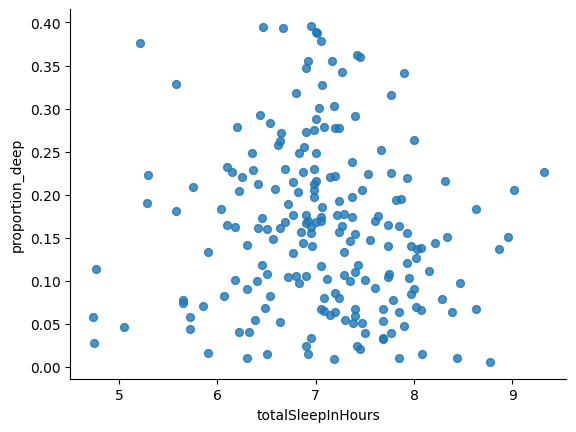

In [ ]:
sleeps_dailies_clean.plot(kind='scatter', x='totalSleepInHours', y='proportion_deep', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

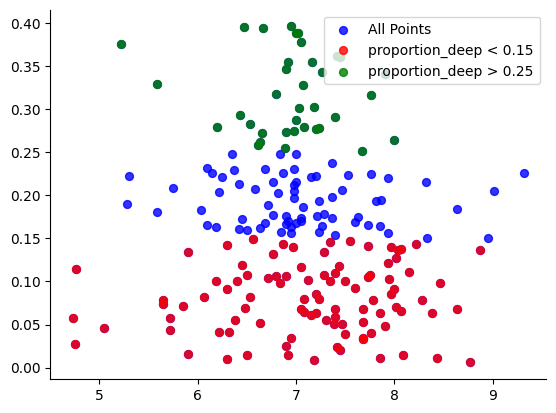

In [ ]:
plt.scatter(x=sleeps_dailies_clean['totalSleepInHours'], y=sleeps_dailies_clean['proportion_deep'],
            s=32, alpha=.8, color='blue', label='All Points')

filtered_rows_low = sleeps_dailies_clean[sleeps_dailies_clean['proportion_deep'] < 0.15]
plt.scatter(x=filtered_rows_low['totalSleepInHours'], y=filtered_rows_low['proportion_deep'],
            s=32, alpha=.8, color='red', label='proportion_deep < 0.15')

filtered_rows_high = sleeps_dailies_clean[sleeps_dailies_clean['proportion_deep'] > 0.25]
plt.scatter(x=filtered_rows_high['totalSleepInHours'], y=filtered_rows_high['proportion_deep'],
            s=32, alpha=.8, color='green', label='proportion_deep > 0.25')

plt.gca().spines[['top', 'right']].set_visible(False)

plt.legend()
plt.show()

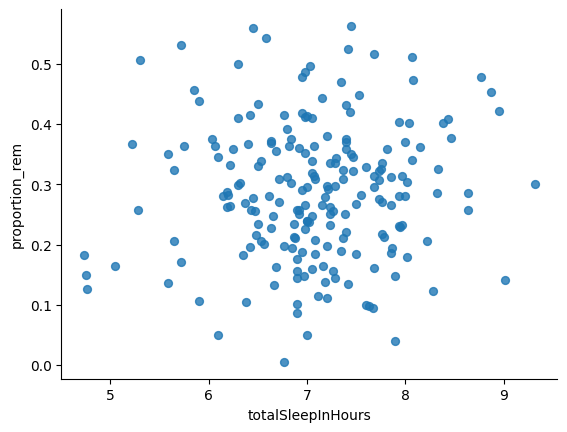

In [ ]:
sleeps_dailies_clean.plot(kind='scatter', x='totalSleepInHours', y='proportion_rem', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

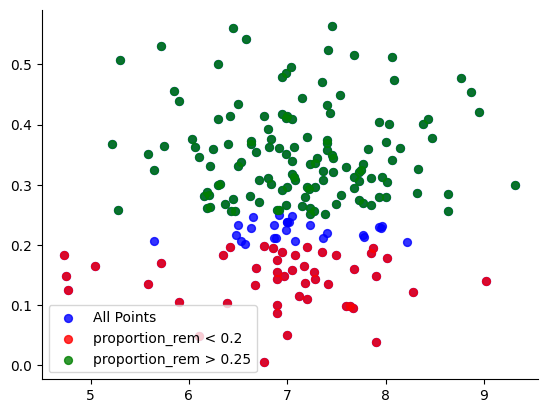

In [ ]:
plt.scatter(x=sleeps_dailies_clean['totalSleepInHours'], y=sleeps_dailies_clean['proportion_rem'],
            s=32, alpha=.8, color='blue', label='All Points')

filtered_rows_low = sleeps_dailies_clean[sleeps_dailies_clean['proportion_rem'] < 0.2]
plt.scatter(x=filtered_rows_low['totalSleepInHours'], y=filtered_rows_low['proportion_rem'],
            s=32, alpha=.8, color='red', label='proportion_rem < 0.2')

filtered_rows_high = sleeps_dailies_clean[sleeps_dailies_clean['proportion_rem'] > 0.25]
plt.scatter(x=filtered_rows_high['totalSleepInHours'], y=filtered_rows_high['proportion_rem'],
            s=32, alpha=.8, color='green', label='proportion_rem > 0.25')

plt.gca().spines[['top', 'right']].set_visible(False)

plt.legend()
plt.show()

In [ ]:
sleeps_dailies_clean['sleepScore'] = 5*sleeps_dailies_clean['proportion_deep']

condition_1 = (sleeps_dailies_clean['proportion_deep'].between(0.15, 0.25)) & (sleeps_dailies_clean['proportion_rem'].between(0.2, 0.25))
condition_2 = (sleeps_dailies_clean['proportion_deep'].between(0.15, 0.25)) & (sleeps_dailies_clean['proportion_rem'] > 0.25)
condition_3 = (sleeps_dailies_clean['proportion_deep'] > 0.25) & (sleeps_dailies_clean['proportion_rem'].between(0.2, 0.25))
condition_4 = (sleeps_dailies_clean['proportion_deep'].between(0.15, 0.25)) & (sleeps_dailies_clean['proportion_rem'] < 0.2)
condition_5 = (sleeps_dailies_clean['proportion_deep'] < 0.15) & (sleeps_dailies_clean['proportion_rem'].between(0.2, 0.25))
condition_6 = (sleeps_dailies_clean['proportion_deep'] > 0.25) & (sleeps_dailies_clean['proportion_rem'] > 0.25)
condition_7 = (sleeps_dailies_clean['proportion_deep'] > 0.25) & (sleeps_dailies_clean['proportion_rem'] < 0.2)
condition_8 = (sleeps_dailies_clean['proportion_deep'] < 0.15) & (sleeps_dailies_clean['proportion_rem'] > 0.25)

sleeps_dailies_clean.loc[condition_1, 'sleepScore'] = 35*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_2, 'sleepScore'] = 25*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_3, 'sleepScore'] = 25*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_4, 'sleepScore'] = 20*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_5, 'sleepScore'] = 20*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_6, 'sleepScore'] = 20*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_7, 'sleepScore'] = 15*sleeps_dailies_clean['proportion_deep']
sleeps_dailies_clean.loc[condition_8, 'sleepScore'] = 15*sleeps_dailies_clean['proportion_deep']

sleeps_dailies_clean['sleepScore'] = sleeps_dailies_clean['sleepScore'].round(3)
sleeps_dailies_clean.to_csv('sleeps_dailies_clean.csv', index = False)
sleeps_dailies_clean

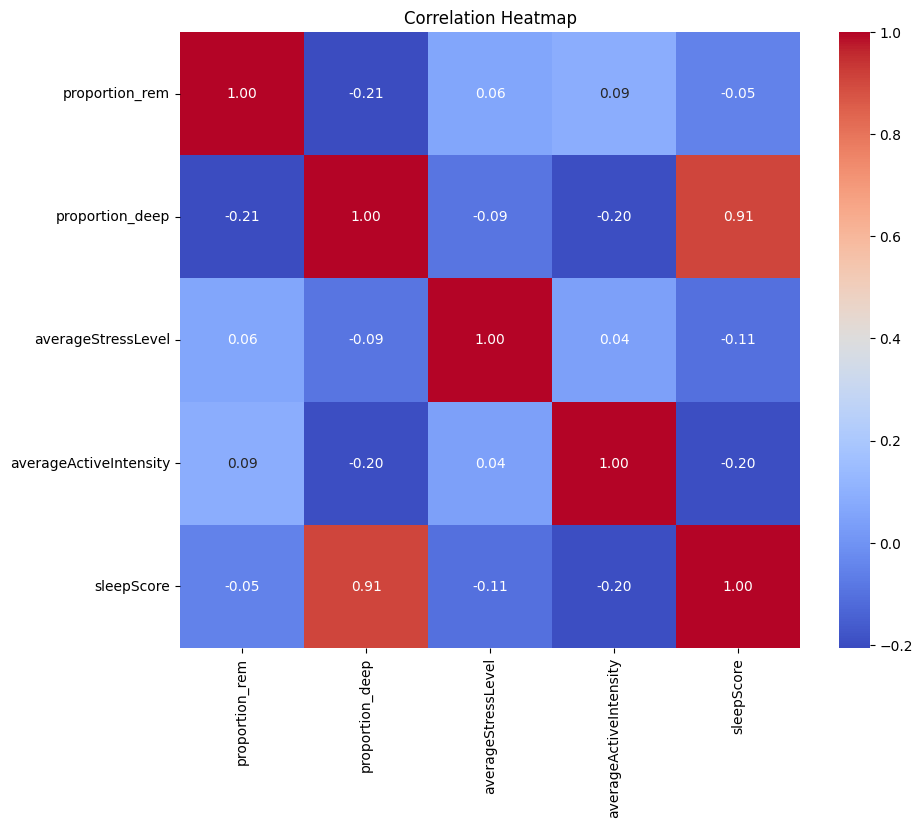

In [ ]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

selected_columns = ['proportion_rem', 'proportion_deep', 'averageStressLevel', 'averageActiveIntensity', 'sleepScore']

selected_data = sleeps_dailies_clean[selected_columns]

correlation_matrix = selected_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()